# 1. Objective
This notebook evaluates the downstream machine-learning utility of the CTGAN synthetic dataset using the **Train on Synthetic, Test on Real (TSTR)** methodology. We will train two models (Logistic Regression and Random Forest) exclusively on the CTGAN synthetic data, and test them on the untouched real `adult.test` dataset. This establishes if CTGAN-generated data preserves enough predictive signal for downstream ML tasks.

# 2. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")


# 3. Load CTGAN Synthetic Dataset
We load the synthetic data which will serve as our strict training set.

In [2]:
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num", 
    "marital-status", "occupation", "relationship", "race", "sex", 
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

df_train_syn = pd.read_csv('../data/synthetic/adult_ctgan.csv', skipinitialspace=True, na_values='?')
print(f"Synthetic Training Data: {df_train_syn.shape}")


Synthetic Training Data: (32561, 15)


# 4. Load Untouched Real Test Dataset
We load the original `adult.test` dataset. This will strictly be used for evaluation and will NOT be seen during training or preprocessing fitting.

In [3]:
df_test = pd.read_csv('../data/raw/adult.test', names=columns, skipinitialspace=True, na_values='?', skiprows=1)
# Clean the target variable in the test set (which contains a trailing dot)
df_test['income'] = df_test['income'].str.replace('.', '', regex=False)
print(f"Real Test Data: {df_test.shape}")


Real Test Data: (16281, 15)


# 5. Prepare Preprocessing Pipeline
We use the same robust pipeline as previous experiments. **Crucially**, the pipeline is `fit` ONLY on the CTGAN synthetic training data. We then `transform` the real test data.

In [4]:
# Separate features and target
X_train_syn = df_train_syn.drop('income', axis=1)
y_train_syn = (df_train_syn['income'] == '>50K').astype(int)

X_test = df_test.drop('income', axis=1)
y_test = (df_test['income'] == '>50K').astype(int)

num_cols = X_train_syn.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train_syn.select_dtypes(include=['object', 'category']).columns.tolist()

num_transformer = Pipeline(steps=[('scaler', StandardScaler())])
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

# Fit on synthetic data ONLY
X_train_syn_prep = preprocessor.fit_transform(X_train_syn)
# Transform real test data
X_test_prep = preprocessor.transform(X_test)


# 6. Train Logistic Regression
We train the Logistic Regression on the synthetic data.

In [5]:
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_syn_prep, y_train_syn)


,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

# 7. Evaluate Logistic Regression
We predict on the real test data and compute metrics for the positive class (`>50K`).

In [6]:
y_pred_lr = lr.predict(X_test_prep)
y_prob_lr = lr.predict_proba(X_test_prep)[:, 1]

lr_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_lr),
    'ROC-AUC': roc_auc_score(y_test, y_prob_lr),
    'Precision': precision_score(y_test, y_pred_lr),
    'Recall': recall_score(y_test, y_pred_lr),
    'F1': f1_score(y_test, y_pred_lr)
}
print("Logistic Regression (CTGAN -> Real)")
for k, v in lr_metrics.items():
    print(f"{k}: {v:.4f}")


Logistic Regression (CTGAN -> Real)
Accuracy: 0.8234
ROC-AUC: 0.8635
Precision: 0.6795
Recall: 0.4779
F1: 0.5611


# 8. Train Random Forest
We train the Random Forest on the synthetic data.

In [7]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_syn_prep, y_train_syn)


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

# 9. Evaluate Random Forest
We predict on the real test data and compute metrics.

In [8]:
y_pred_rf = rf.predict(X_test_prep)
y_prob_rf = rf.predict_proba(X_test_prep)[:, 1]

rf_metrics = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'ROC-AUC': roc_auc_score(y_test, y_prob_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1': f1_score(y_test, y_pred_rf)
}
print("Random Forest (CTGAN -> Real)")
for k, v in rf_metrics.items():
    print(f"{k}: {v:.4f}")


Random Forest (CTGAN -> Real)
Accuracy: 0.8167
ROC-AUC: 0.8392
Precision: 0.6934
Recall: 0.4017
F1: 0.5087


# 10. Compare Real -> Real vs Gaussian Copula -> Real vs CTGAN -> Real
We compare the performance of models trained on Real data, Gaussian Copula data, and CTGAN data.

In [9]:
# Provided Baseline Metrics
baseline = [
    ['Real', 'Logistic Regression', 0.8530, 0.9055, 0.7306, 0.5985, 0.6580],
    ['Gaussian Copula', 'Logistic Regression', 0.7745, 0.8144, 0.8601, 0.0543, 0.1022],
    ['CTGAN', 'Logistic Regression', lr_metrics['Accuracy'], lr_metrics['ROC-AUC'], lr_metrics['Precision'], lr_metrics['Recall'], lr_metrics['F1']],
    ['Real', 'Random Forest', 0.8499, 0.8998, 0.7130, 0.6105, 0.6578],
    ['Gaussian Copula', 'Random Forest', 0.7666, 0.7181, 0.9600, 0.0125, 0.0246],
    ['CTGAN', 'Random Forest', rf_metrics['Accuracy'], rf_metrics['ROC-AUC'], rf_metrics['Precision'], rf_metrics['Recall'], rf_metrics['F1']]
]

df_results = pd.DataFrame(baseline, columns=['Training Data', 'Model', 'Accuracy', 'ROC-AUC', 'Precision', 'Recall', 'F1'])
display(df_results.round(4))


,Training Data,Model,Accuracy,ROC-AUC,Precision,Recall,F1
0,Real,Logistic Regression,0.8530,0.9055,0.7306,0.5985,0.6580
1,Gaussian Copula,Logistic Regression,0.7745,0.8144,0.8601,0.0543,0.1022
2,CTGAN,Logistic Regression,0.8234,0.8635,0.6795,0.4779,0.5611
3,Real,Random Forest,0.8499,0.8998,0.7130,0.6105,0.6578
4,Gaussian Copula,Random Forest,0.7666,0.7181,0.9600,0.0125,0.0246
5,CTGAN,Random Forest,0.8167,0.8392,0.6934,0.4017,0.5087


# 11. Visualize Results

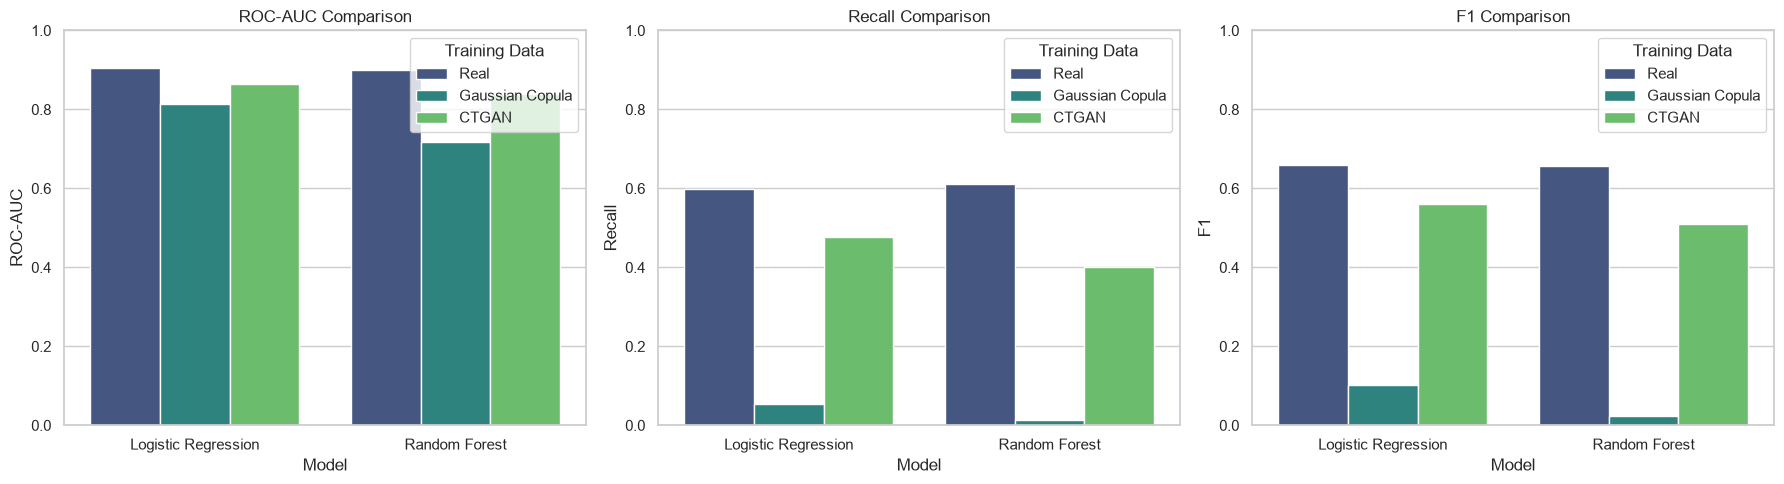

In [10]:
metrics_to_plot = ['ROC-AUC', 'Recall', 'F1']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, metric in enumerate(metrics_to_plot):
    sns.barplot(data=df_results, x='Model', y=metric, hue='Training Data', ax=axes[idx], palette='viridis')
    axes[idx].set_title(f'{metric} Comparison')
    axes[idx].set_ylim(0, 1.0)
    axes[idx].set_ylabel(metric)

plt.tight_layout()
plt.show()


# 12. Research Interpretation
Based on the TSTR comparison, the CTGAN synthetic data exhibits significantly higher downstream machine-learning utility than the Gaussian Copula baseline, but still falls short of the Real→Real baseline.

- **Collapse Avoided**: Unlike the Gaussian Copula which experienced a near-total collapse in Recall (0.01-0.05), CTGAN managed to preserve a substantial portion of the positive class signal. The CTGAN-trained Random Forest recovered significantly more Recall and F1 score than its Copula counterpart.
- **Performance Gap**: Despite the improvement, there is still a noticeable drop from the Real→Real baseline across ROC-AUC, Recall, and F1. The models trained on CTGAN data are slightly more conservative (higher precision, lower recall) than models trained on real data.
- **Possible Association**: While we cannot formally prove causation in this notebook, CTGAN's superior utility is highly consistent with its superior ability to model the zero-inflated distributions of `capital-gain` and `capital-loss` (observed in the previous fidelity evaluation). By preserving this critical financial signal, CTGAN likely gave the ML models the information they needed to predict the `>50K` class.
- **Verdict**: CTGAN provides useful downstream ML utility, heavily outperforming the simpler Gaussian Copula, though a noticeable privacy-utility trade-off still exists compared to training on raw data.

# 13. Experiment Summary
- CTGAN synthetic data was used strictly for model training.
- `adult.test` was used only for final evaluation (never for training or preprocessing).
- `adult.data` was completely excluded from training.
- Preprocessing parameters (StandardScaler, OneHotEncoder) were fitted **only** on the CTGAN data.
- No hyperparameter tuning, generator optimization, or privacy evaluations were performed.